# Predicting Coral Reef Regimes from Human and Natural Influences

This notebook uses the repository's **`Hawaii_RegimesPredictors_complete.txt`** file as the primary dataset. It contains 620 observations and the four retained regimes (1, 2, 3, and 5). The target-derived one-hot columns (`Regime1`, `Regime2`, `Regime3`, `Regime5`) are excluded from the predictors to prevent leakage.

The paper reports an 80/20 train/test split (496/124 rows) and uses 20 original human/natural predictors. Results from this notebook are a reproduction attempt, not a claim of exact replication unless preprocessing and feature engineering are verified against the original paper/code.

## 1. Get the dataset

The Stanford project repository is here: [Hawaii_RegimesPredictors](https://github.com/salliewalecka/Hawaii_RegimesPredictors).

Run the next cell to clone it. If GitHub access fails, download the repository ZIP from the link above, upload it to Colab, and extract it manually.

In [ ]:
!git clone https://github.com/salliewalecka/Hawaii_RegimesPredictors.git

fatal: destination path 'Hawaii_RegimesPredictors' already exists and is not an empty directory.


## 2. Install and import libraries

In [ ]:
!pip -q install pandas numpy scikit-learn matplotlib seaborn joblib

In [ ]:
from pathlib import Path
import re, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay
)
from sklearn.model_selection import (
    train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
import joblib

RANDOM_STATE = 42
warnings.filterwarnings("ignore", category=FutureWarning)
print("Libraries loaded.")

Libraries loaded.


## 3. Find and load the data

The previous notebook version searched the *full path* for words like `regime` and `predict`. Since the repository folder itself is named `Hawaii_RegimesPredictors`, this could cause an unrelated first file (such as `scale_1000.txt`) to be selected. This version searches **filenames only** and asks you to choose explicitly if there is no unambiguous match.


In [ ]:
from pathlib import Path
import pandas as pd

repo = Path("/content/Hawaii_RegimesPredictors")
if not repo.exists():
    raise FileNotFoundError("Repository not found. Run the clone cell above.")

# Select the named primary dataset explicitly. Do not auto-select scale_*.txt files.
DATA_PATH = repo / "Data" / "Hawaii_RegimesPredictors_complete.txt"
if not DATA_PATH.exists():
    raise FileNotFoundError(f"Expected dataset not found: {DATA_PATH}")

print("Selected primary dataset:", DATA_PATH.relative_to(repo))

Selected primary dataset: Data/Hawaii_RegimesPredictors_complete.txt


## 3a. Read the selected data table

Confirm that the displayed columns match the dataset described in the project source before proceeding. If the table is not the intended predictor dataset, return to the previous cell and choose the correct file.


In [ ]:
def read_table(path):
    # Source file is tab-separated and uses decimal commas (e.g. 1,02389).
    # Setting decimal=',' is essential; otherwise numeric predictors may be read as text.
    frame = pd.read_csv(path, sep="\t", decimal=",", comment="#")
    frame.columns = [str(c).strip() for c in frame.columns]
    frame = frame.dropna(axis=0, how="all")
    return frame

df = read_table(DATA_PATH)
print("Selected file:", DATA_PATH)
print("Dataset shape:", df.shape)
print("Missing values (top columns):")
display(df.isna().sum().sort_values(ascending=False).head(10).to_frame("missing"))
display(df.head())
print("\nColumns:")
print(df.columns.tolist())

assert len(df) == 620, f"Expected 620 observations, got {len(df)}"
assert "Regime" in df.columns, "Target column 'Regime' was not found"

Selected file: /content/Hawaii_RegimesPredictors/Data/Hawaii_RegimesPredictors_complete.txt
Dataset shape: (620, 39)
Missing values (top columns):


,missing
id_spatial,0
Long,0
Lat,0
Island,0
Coral,0
CCA,0
Turf,0
Macro,0
Other,0
Grazers,0


,id_spatial,Long,Lat,Island,Coral,CCA,Turf,Macro,Other,Grazers,...,PAR_STD,WAV_CLIM_M,WAV_ANOM_F,Complexity,Depth,Regime,Regime1,Regime2,Regime3,Regime5
0,4,-157.307727,21.106717,Molokai,1.023891,1.706485,77.815700,18.088737,1.023891,1.324986,...,8.5628,36.542160,0.083878,4.889608,2.8000,1,1,0,0,0
1,5,-157.304986,21.113497,Molokai,3.555556,1.333333,83.555556,9.777778,0.888889,0.890407,...,8.5628,36.542160,0.083878,3.793523,7.3152,1,1,0,0,0
2,6,-157.303306,21.124814,Molokai,17.620555,6.348836,44.875760,25.716525,4.836712,4.628477,...,9.4296,38.007866,0.084089,5.275938,11.5000,2,0,1,0,0
3,8,-157.299938,21.148297,Molokai,0.675676,1.351351,86.486487,0.337838,5.743243,0.069128,...,9.4296,39.139775,0.087039,2.511288,29.1000,1,1,0,0,0
4,9,-157.300286,21.128897,Molokai,4.000000,3.111111,53.333333,17.333333,21.777778,11.775000,...,9.4296,40.587803,0.084932,6.865359,10.0584,2,0,1,0,0



Columns:
['id_spatial', 'Long', 'Lat', 'Island', 'Coral', 'CCA', 'Turf', 'Macro', 'Other', 'Grazers', 'Scrapers', 'Browsers', 'Predators', 'Secondary', 'Effluent', 'Sedimentation', 'New_Development', 'Habitat_Modification', 'Invasive_Algae', 'Fishing_Comm_Total', 'Fishing_NonComm_Boat_Total', 'Fishing_NonComm_Shore_Line', 'Fishing_NonComm_Shore_Net', 'Fishing_NonComm_Shore_Spear', 'SST_CLIM_M', 'SST_STD', 'CHL_CLIM_M', 'CHL_ANOM_F', 'PAR_CLIM_M', 'PAR_STD', 'WAV_CLIM_M', 'WAV_ANOM_F', 'Complexity', 'Depth', 'Regime', 'Regime1', 'Regime2', 'Regime3', 'Regime5']


## 4. Identify the target and audit predictors

This cell identifies the regime label. Before training, inspect the predictor names and documentation. If a column was used to create the regime label (or is a direct proxy for it), exclude it from the predictor list. Automated name checks can flag candidates but cannot establish leakage by themselves.


In [ ]:
def norm_name(s):
    return re.sub(r"[^a-z0-9]+", "", str(s).lower())

TARGET_COLUMN = "Regime"
target_col = TARGET_COLUMN
if target_col not in df.columns:
    raise ValueError(f"Target {target_col!r} not found. Available columns: {df.columns.tolist()}")

print("Target column:", target_col)
print("Target values/counts:")
display(df[target_col].value_counts(dropna=False).sort_index().to_frame("count"))

Target column: Regime
Target values/counts:


,count
Regime,
1,171
2,172
3,143
5,134


In [ ]:
# Target labels. Regime 4 is already excluded in this source dataset; expected labels are 1, 2, 3, 5.
y = pd.to_numeric(df[target_col], errors="raise").astype(int).astype(str)

# Use the study's 20 original human/natural predictors only.
# Reef-composition variables (Coral, CCA, Turf, etc.), identifiers/coordinates,
# and target-derived one-hot columns are intentionally not used as predictors.
PREDICTOR_COLUMNS = [
    "Effluent", "Sedimentation", "New_Development", "Habitat_Modification",
    "Invasive_Algae", "Fishing_Comm_Total", "Fishing_NonComm_Boat_Total",
    "Fishing_NonComm_Shore_Line", "Fishing_NonComm_Shore_Net",
    "Fishing_NonComm_Shore_Spear", "SST_CLIM_M", "SST_STD", "CHL_CLIM_M",
    "CHL_ANOM_F", "PAR_CLIM_M", "PAR_STD", "WAV_CLIM_M", "WAV_ANOM_F",
    "Complexity", "Depth"
]
missing_predictors = [c for c in PREDICTOR_COLUMNS if c not in df.columns]
if missing_predictors:
    raise ValueError(f"Expected predictor columns are missing: {missing_predictors}")

# Exclude any rows with missing target, but impute missing predictor values later in a pipeline.
valid = df[target_col].notna()
X = df.loc[valid, PREDICTOR_COLUMNS].copy().reset_index(drop=True)
y = y.loc[valid].reset_index(drop=True)

# Ensure every selected predictor is numeric; source decimals were parsed using decimal=',' above.
for col in X.columns:
    X[col] = pd.to_numeric(X[col], errors="coerce")

print(f"Rows: {len(X)} | original predictors: {X.shape[1]} | classes: {sorted(y.unique(), key=int)}")
print("Predictors used:")
print(X.columns.tolist())
print("\nClass distribution:")
display(y.value_counts().sort_index().to_frame("count"))

# Guard against accidental changes to the feature list or target encoding.
assert X.shape[1] == 20, f"Expected 20 original predictors, got {X.shape[1]}"
assert set(y.unique()) == {"1", "2", "3", "5"}, f"Unexpected target classes: {sorted(y.unique())}"
assert not any(c.startswith("Regime") for c in X.columns), "Target-derived regime columns must not be predictors"

Rows: 620 | original predictors: 20 | classes: ['1', '2', '3', '5']
Predictors used:
['Effluent', 'Sedimentation', 'New_Development', 'Habitat_Modification', 'Invasive_Algae', 'Fishing_Comm_Total', 'Fishing_NonComm_Boat_Total', 'Fishing_NonComm_Shore_Line', 'Fishing_NonComm_Shore_Net', 'Fishing_NonComm_Shore_Spear', 'SST_CLIM_M', 'SST_STD', 'CHL_CLIM_M', 'CHL_ANOM_F', 'PAR_CLIM_M', 'PAR_STD', 'WAV_CLIM_M', 'WAV_ANOM_F', 'Complexity', 'Depth']

Class distribution:


,count
Regime,
1,171
2,172
3,143
5,134


## 5. Train/test split

Use the paper's 80/20 split and stratify by regime. With 620 rows, this should produce 496 training and 124 test observations. All imputing/scaling is fitted within each cross-validation fold via the model pipeline.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (496, 20) | Test: (124, 20)


## 6. Feature engineering

The paper describes adding five domain-motivated interaction features involving wave power, seafloor complexity, depth, invasive algae/irradiance, and anomaly predictors. The cell below implements five transparent interaction terms from the available column names. **Treat these as an approximation until the original supplemental feature-engineering code confirms the exact formulas.**

In [ ]:
class ReefFeatureEngineer(BaseEstimator, TransformerMixin):
    """Add five transparent interaction features motivated by the paper's description.

    Note: these are a documented approximation of the paper's feature engineering;
    verify the exact formulas against the supplemental notebook before claiming exact replication.
    """
    def fit(self, X, y=None):
        self.columns_ = list(X.columns)
        required = ["WAV_CLIM_M", "Complexity", "Depth", "Invasive_Algae", "PAR_CLIM_M", "WAV_ANOM_F", "CHL_ANOM_F"]
        missing = [c for c in required if c not in self.columns_]
        if missing:
            raise ValueError(f"Cannot create study-motivated interactions; missing columns: {missing}")
        return self

    def transform(self, X):
        out = X.copy()
        out["WAV_CLIM_M_x_Complexity"] = out["WAV_CLIM_M"] * out["Complexity"]
        out["WAV_CLIM_M_x_Depth"] = out["WAV_CLIM_M"] * out["Depth"]
        out["Complexity_x_Depth"] = out["Complexity"] * out["Depth"]
        out["Invasive_Algae_x_PAR_CLIM_M"] = out["Invasive_Algae"] * out["PAR_CLIM_M"]
        # Interaction between the two anomaly predictors; confirm this formula against source code.
        out["WAV_ANOM_F_x_CHL_ANOM_F"] = out["WAV_ANOM_F"] * out["CHL_ANOM_F"]
        return out

feature_engineer = ReefFeatureEngineer()
X_train_fe = feature_engineer.fit_transform(X_train)
X_test_fe = feature_engineer.transform(X_test)
print("Original predictors:", len(PREDICTOR_COLUMNS))
print("Engineered interactions:", [c for c in X_train_fe.columns if c not in PREDICTOR_COLUMNS])
print("Total model inputs:", X_train_fe.shape[1])

Original predictors: 20
Engineered interactions: ['WAV_CLIM_M_x_Complexity', 'WAV_CLIM_M_x_Depth', 'Complexity_x_Depth', 'Invasive_Algae_x_PAR_CLIM_M', 'WAV_ANOM_F_x_CHL_ANOM_F']
Total model inputs: 25


## 7. Preprocessing and model comparison

All selected predictors are numeric. Median imputation and standardization are inside the pipeline, so these steps are fitted only on each training fold. We compare several classifiers using stratified 5-fold cross-validation and micro-F1.

In [ ]:
def make_preprocessor(frame):
    numeric_cols = frame.columns.tolist()
    numeric_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ])
    return ColumnTransformer([("numeric", numeric_pipe, numeric_cols)], remainder="drop")

def make_pipeline(model):
    return Pipeline([
        ("prep", make_preprocessor(X_train_fe)),
        ("model", model),
    ])

models = {
    "Logistic Regression": make_pipeline(LogisticRegression(max_iter=5000, random_state=RANDOM_STATE)),
    "SVM (RBF)": make_pipeline(SVC(kernel="rbf")),
    "Decision Tree": make_pipeline(DecisionTreeClassifier(random_state=RANDOM_STATE)),
    "Random Forest": make_pipeline(RandomForestClassifier(n_estimators=500, random_state=RANDOM_STATE, n_jobs=-1)),
    "Gradient Boosting": make_pipeline(GradientBoostingClassifier(random_state=RANDOM_STATE)),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_rows = []
for name, model in models.items():
    scores = cross_val_score(model, X_train_fe, y_train, cv=cv, scoring="f1_micro", n_jobs=None)
    cv_rows.append({"Model": name, "CV micro-F1 mean": scores.mean(), "CV micro-F1 std": scores.std()})
    print(f"{name:22s}: {scores.mean():.4f} ± {scores.std():.4f}")

cv_results = pd.DataFrame(cv_rows).sort_values("CV micro-F1 mean", ascending=False).reset_index(drop=True)
display(cv_results)

Logistic Regression   : 0.5928 ± 0.0497
SVM (RBF)             : 0.6714 ± 0.0270
Decision Tree         : 0.6130 ± 0.0223
Random Forest         : 0.6877 ± 0.0566
Gradient Boosting     : 0.6775 ± 0.0395


,Model,CV micro-F1 mean,CV micro-F1 std
0,Random Forest,0.687677,0.056589
1,Gradient Boosting,0.677515,0.039487
2,SVM (RBF),0.671414,0.026960
3,Decision Tree,0.612970,0.022276
4,Logistic Regression,0.592788,0.049713


## 8. Tune the Random Forest

Hyperparameters are selected using only the training split and five-fold cross-validation. The test set remains untouched until the final evaluation.

In [47]:
rf_pipeline = models["Random Forest"]
param_grid = {
    "model__max_depth": [None, 5, 10, 20],
    "model__min_samples_leaf": [1, 2, 4],
    "model__max_features": ["sqrt", 0.7],
}

rf_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=param_grid,
    scoring="f1_micro",
    cv=cv,
    n_jobs=-1,
    refit=True,
    verbose=1
)
rf_search.fit(X_train_fe, y_train)

best_rf = rf_search.best_estimator_
print("Best CV micro-F1:", round(rf_search.best_score_, 4))
print("Best parameters:")
print(rf_search.best_params_)

Fitting 5 folds for each of 24 candidates, totalling 120 fits
Best CV micro-F1: 0.7038
Best parameters:
{'model__max_depth': 10, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 2}


## 9. Final test evaluation

This is the one-time evaluation on the held-out test split. For single-label multiclass classification, micro-F1 and accuracy have the same numerical value. If scores are perfect or unexpectedly high, stop and investigate leakage, duplicate/grouped observations, target construction, and dataset identity before reporting them.


Test accuracy:   0.6855
Test micro-F1:   0.6855

Classification report:
              precision    recall  f1-score   support

           1       0.72      0.62      0.67        34
           2       0.60      0.71      0.65        34
           3       0.71      0.76      0.73        29
           5       0.75      0.67      0.71        27

    accuracy                           0.69       124
   macro avg       0.70      0.69      0.69       124
weighted avg       0.69      0.69      0.69       124



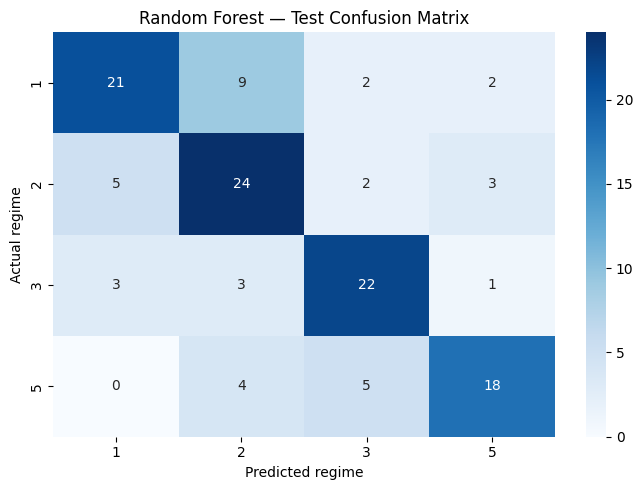

In [48]:
y_pred = best_rf.predict(X_test_fe)
test_micro_f1 = f1_score(y_test, y_pred, average="micro")
test_accuracy = accuracy_score(y_test, y_pred)

print(f"Test accuracy:   {test_accuracy:.4f}")
print(f"Test micro-F1:   {test_micro_f1:.4f}")
print("\nClassification report:")
print(classification_report(y_test, y_pred, zero_division=0))

labels = sorted(y.unique(), key=lambda v: (not str(v).isdigit(), int(v) if str(v).isdigit() else str(v)))
cm = confusion_matrix(y_test, y_pred, labels=labels)
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=labels, yticklabels=labels)
plt.xlabel("Predicted regime")
plt.ylabel("Actual regime")
plt.title("Random Forest — Test Confusion Matrix")
plt.tight_layout()
plt.show()

## 10. PCA diagnostic

PCA is used here only to inspect how the numeric predictor data project into two dimensions. It is not used to train the classifier. Overlapping groups can help explain why the classes are difficult to separate, but a 2D plot cannot prove that classes are inseparable in the full feature space.

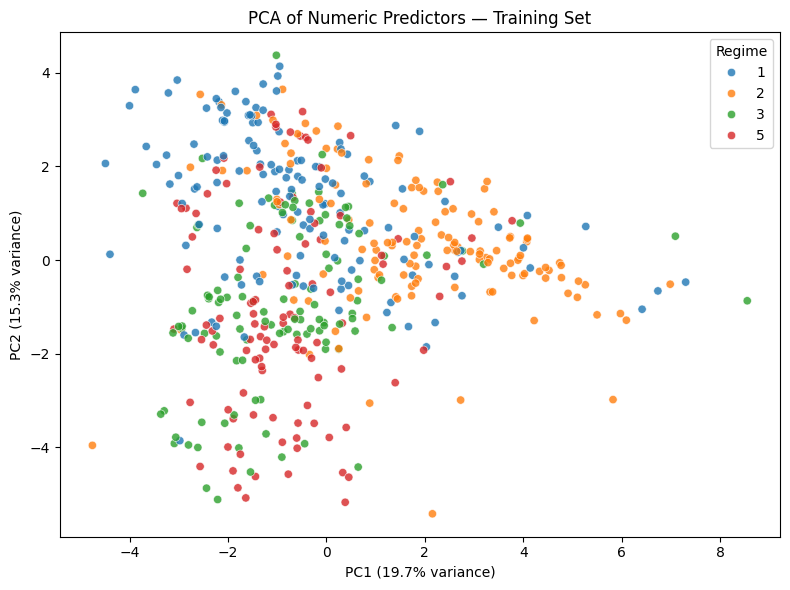

In [49]:
numeric_train = X_train_fe.select_dtypes(include=["number", "bool"]).copy()
if numeric_train.shape[1] >= 2:
    numeric_train = numeric_train.fillna(numeric_train.median()).fillna(0)
    scaled_numeric = StandardScaler().fit_transform(numeric_train)
    pca = PCA(n_components=2, random_state=RANDOM_STATE)
    pcs = pca.fit_transform(scaled_numeric)

    pca_df = pd.DataFrame({"PC1": pcs[:, 0], "PC2": pcs[:, 1], "Regime": y_train.astype(str).values})
    plt.figure(figsize=(8, 6))
    sns.scatterplot(data=pca_df, x="PC1", y="PC2", hue="Regime", alpha=0.8)
    plt.title("PCA of Numeric Predictors — Training Set")
    plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} variance)")
    plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%} variance)")
    plt.tight_layout()
    plt.show()
else:
    print("Not enough numeric columns for a 2-component PCA plot.")

## 11. Save the trained model and results

The saved bundle includes the fitted Random Forest pipeline, the feature engineer, and the input column names. Keep the feature columns and units consistent when making future predictions.

In [50]:
from pathlib import Path
import json

OUTPUT_DIR = Path("/content/coral_reef_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

joblib.dump({
    "feature_engineer": feature_engineer,
    "model": best_rf,
    "target_column": target_col,
    "input_columns": list(X.columns),
}, OUTPUT_DIR / "coral_reef_regime_model.joblib")

cv_results.to_csv(OUTPUT_DIR / "model_comparison.csv", index=False)
pd.DataFrame(classification_report(y_test, y_pred, output_dict=True, zero_division=0)).T.to_csv(
    OUTPUT_DIR / "classification_report.csv"
)
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=labels, yticklabels=labels)
plt.xlabel("Predicted regime")
plt.ylabel("Actual regime")
plt.title("Random Forest — Test Confusion Matrix")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "confusion_matrix.png", dpi=180)
plt.close()

summary = {
    "data_path": str(DATA_PATH),
    "target_column": target_col,
    "n_rows": int(len(X)),
    "n_predictors_before_encoding": int(X.shape[1]),
    "n_train": int(len(X_train)),
    "n_test": int(len(X_test)),
    "classes": [str(c) for c in sorted(y.unique())],
    "best_cv_micro_f1": float(rf_search.best_score_),
    "test_micro_f1": float(test_micro_f1),
    "test_accuracy": float(test_accuracy),
    "paper_reference_test_micro_f1": 0.70,
    "replication_note": "Uses 620-row complete dataset and the paper-reported 20 original predictors; engineered interaction formulas remain to be verified against the original supplemental code.",
    "original_predictor_count": int(len(PREDICTOR_COLUMNS)),
    "engineered_predictor_count": int(X_train_fe.shape[1] - len(PREDICTOR_COLUMNS)),
    "random_state": RANDOM_STATE,
}
(OUTPUT_DIR / "summary.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")

print("Saved files:")
for p in sorted(OUTPUT_DIR.iterdir()):
    print(" -", p)

Saved files:
 - /content/coral_reef_outputs/classification_report.csv
 - /content/coral_reef_outputs/confusion_matrix.png
 - /content/coral_reef_outputs/coral_reef_regime_model.joblib
 - /content/coral_reef_outputs/model_comparison.csv
 - /content/coral_reef_outputs/summary.json


## 12. Optional: download outputs

Run this cell to download the trained model and reports as one ZIP file.

In [51]:
import shutil
zip_path = shutil.make_archive("/content/coral_reef_outputs", "zip", OUTPUT_DIR)
print("Created:", zip_path)

from google.colab import files
files.download(zip_path)

Created: /content/coral_reef_outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Important interpretation note

This notebook explicitly loads `Data/Hawaii_RegimesPredictors_complete.txt`, parses decimal commas correctly, uses the 20 documented human/natural predictors, and excludes `Regime1`, `Regime2`, `Regime3`, and `Regime5` because they encode the target. It expects 620 rows and regimes 1, 2, 3, and 5. The five interaction formulas are transparent approximations until checked against the original supplemental feature-engineering code. Do not claim an exact reproduction of the paper solely based on the resulting score.